### Drehbuch 1.5h Einleitung neuronale Netze

1) Lineare Regression als Modell mit einem Parameter
2) Summe der Residuen als Fehlerfunktion
3) Ableitung als Richtung zum Minimum
4) Micrograd für lineare Regression mit einem Parameter
5) Visuelle Darstellung des Berechnungsgraphen bei linearer Regression
6) Micrograd für lineare Regression mit zwei Parametern
7) Klassifikationsdemo mit nur einem Neuron
8) Klassifikationsdemo mit neuronalem Netz
9) MNIST Klassifikation (eigenes Skript)

#### Lineare Regression mit einem Parameter (Steigung der Geraden)

Animierte Darstellung nur Gerade

In [81]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

# -----------------
# Generate data
# -----------------
np.random.seed(42)
n = 10
x = np.linspace(1, 10, n)
true_beta = 2.0
y = true_beta * x + np.random.normal(0, 2, n)

# -----------------
# Set up figure
# -----------------
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(x, y, label="data")

x_line = np.linspace(0, 10.5, 200)
line, = ax.plot(x_line, np.zeros_like(x_line), label="y = beta1 x")

title = ax.set_title("")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.legend()

# -----------------
# Animation function
# -----------------
def update(beta1):
    y_pred = beta1 * x

    # update line
    line.set_ydata(beta1 * x_line)

    # compute SSE
    sse = np.sum((y - y_pred) ** 2)
#    title.set_text(f"beta1 = {beta1:.2f}   |   SSE = {sse:.2f}")
    title.set_text(f"beta1 = {beta1:.2f}")

    return [line, title]

# sweep beta values back and forth
beta_values = np.concatenate([
    np.linspace(-0.5, 3.5, 80),
    np.linspace(3.5, -0.5, 80)
])

ani = FuncAnimation(fig, update, frames=beta_values, interval=80, blit=False)

plt.close(fig)
HTML(ani.to_jshtml())

Animierte Darstellung mit Residuen

In [82]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

# -----------------
# Generate data
# -----------------
np.random.seed(42)
n = 10
x = np.linspace(1, 10, n)
true_beta = 2.0
y = true_beta * x + np.random.normal(0, 2, n)

# -----------------
# Set up figure
# -----------------
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(x, y, label="data")

x_line = np.linspace(0, 10.5, 200)
line, = ax.plot(x_line, np.zeros_like(x_line), label="y = beta1 x")

residual_lines = []
for xi, yi in zip(x, y):
    seg, = ax.plot([xi, xi], [yi, 0], linestyle="--", color="red", alpha=0.6)
    residual_lines.append(seg)

title = ax.set_title("")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.legend()

def update(beta1):
    y_pred = beta1 * x
    line.set_ydata(beta1 * x_line)

    for seg, xi, yi, ypi in zip(residual_lines, x, y, y_pred):
        seg.set_data([xi, xi], [yi, ypi])

    sse = np.sum((y - y_pred) ** 2)
    title.set_text(f"beta1 = {beta1:.2f}   |   SSE = {sse:.2f}")
    return [line, title, *residual_lines]

beta_values = np.concatenate([
    np.linspace(-0.5, 3.5, 80),
    np.linspace(3.5, -0.5, 80)
])

ani = FuncAnimation(fig, update, frames=beta_values, interval=80, blit=False)

plt.close(fig)  # prevents duplicate static figure
HTML(ani.to_jshtml())

#### Summe der Residuenquadrate als Fehlerfunktion

Animierte Darstellung Modell neben Fehlerfunktion

In [83]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

# -----------------
# Generate data
# -----------------
np.random.seed(42)
n = 10
x = np.linspace(1, 10, n)
true_beta = 2.0
y = true_beta * x + np.random.normal(0, 2, n)

# -----------------
# Beta values for animation
# -----------------
beta_values = np.concatenate([
    np.linspace(-0.5, 3.5, 80),
    np.linspace(3.5, -0.5, 80)
])

# -----------------
# Precompute SSE curve
# -----------------
beta_grid = np.linspace(-0.5, 3.5, 300)
sse_grid = np.array([np.sum((y - b * x) ** 2) for b in beta_grid])

# -----------------
# Set up figure with 2 panels
# -----------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

# ---- Left plot: data + regression line + residuals
ax1.scatter(x, y, label="data", s=35)

x_line = np.linspace(0, 10.5, 200)
line, = ax1.plot(x_line, np.zeros_like(x_line), label="y = beta1 x")

residual_lines = []
for xi, yi in zip(x, y):
    seg, = ax1.plot(
        [xi, xi], [yi, 0],
        linestyle="--",
        color="red",
        alpha=0.6,
        linewidth=1
    )
    residual_lines.append(seg)

title1 = ax1.set_title("")
ax1.set_xlabel("x")
ax1.set_ylabel("y")
ax1.legend(loc="upper left")
ax1.set_xlim(0, 10.5)

# fix y-limits so animation doesn't rescale
y_min = min(y.min(), (beta_values.min() * x).min()) - 2
y_max = max(y.max(), (beta_values.max() * x).max()) + 2
ax1.set_ylim(y_min, y_max)

# ---- Right plot: SSE as function of beta1
ax2.plot(beta_grid, sse_grid, label="SSE(beta1)")
point, = ax2.plot([beta_values[0]], [np.sum((y - beta_values[0] * x) ** 2)], marker="o")

ax2.set_xlabel("beta1")
ax2.set_ylabel("SSE")
ax2.set_title("SSE vs beta1")
ax2.legend()
ax2.set_xlim(beta_grid.min(), beta_grid.max())
ax2.set_ylim(0, sse_grid.max() * 1.05)

# Optional: show best beta as vertical line
# beta_hat = np.sum(x * y) / np.sum(x**2)
# ax2.axvline(beta_hat, linestyle="--", alpha=0.6)

# -----------------
# Animation function
# -----------------
def update(beta1):
    y_pred = beta1 * x

    # Left panel: update regression line
    line.set_ydata(beta1 * x_line)

    # Left panel: update residuals
    for seg, xi, yi, ypi in zip(residual_lines, x, y, y_pred):
        seg.set_data([xi, xi], [yi, ypi])

    sse = np.sum((y - y_pred) ** 2)

    # Update title
    title1.set_text(f"beta1 = {beta1:.2f}   |   SSE = {sse:.2f}")

    # Right panel: move dot on SSE curve
    point.set_data([beta1], [sse])

    return [line, title1, point, *residual_lines]

ani = FuncAnimation(fig, update, frames=beta_values, interval=80, blit=False)

plt.tight_layout()
plt.close(fig)
HTML(ani.to_jshtml())

#### Ableitung als Richtung zum Minimum

Animation zur Veranschaulichung des Begriffs _Ableitung_

In [84]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
import matplotlib as mpl

mpl.rcParams['animation.embed_limit'] = 50  # MB

# -----------------
# Function
# -----------------
f = lambda x: x**2
fprime = lambda x: 2*x

# -----------------
# Curve data
# -----------------
x_curve = np.linspace(-4, 4, 400)
y_curve = f(x_curve)

# animation frames: point moves left to right
x_values = np.linspace(-3.5, 3.5, 120)

# width of the rise/run triangle
dx = 0.5

# -----------------
# Figure setup
# -----------------
fig, ax = plt.subplots(figsize=(7, 5))

# main curve
ax.plot(x_curve, y_curve, label=r"$f(x)=x^2$")

# moving point
point, = ax.plot([], [], marker="o")

# tangent line
x_tan = np.linspace(-4, 4, 200)
tangent_line, = ax.plot([], [], label="Tangente")

# triangle pieces
run_line, = ax.plot([], [], linestyle="--")
rise_line, = ax.plot([], [], linestyle="--")
hyp_line, = ax.plot([], [], linestyle=":")

# text labels for rise/run
run_text = ax.text(0, 0, "")
rise_text = ax.text(0, 0, "")

ax.set_xlim(-4, 4)
ax.set_ylim(-1, 17)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.legend(loc="upper left")
ax.grid(True, alpha=0.3)

title = ax.set_title("")

# -----------------
# Animation update
# -----------------
def update(frame):
    x0 = x_values[frame]
    y0 = f(x0)
    slope = fprime(x0)

    # tangent line through (x0, y0)
    y_tan = y0 + slope * (x_tan - x0)

    # triangle helper point
    x1 = x0 + dx
    y1 = f(x1)

    # moving point
    point.set_data([x0], [y0])

    # tangent
    tangent_line.set_data(x_tan, y_tan)

    # rise-over-run triangle
    run_line.set_data([x0, x1], [y0, y0])
    rise_line.set_data([x1, x1], [y0, y1])
    hyp_line.set_data([x0, x1], [y0, y1])

    # labels
    #run_text.set_position(((x0 + x1) / 2, y0 - 0.8))
    #run_text.set_text(f"run = {dx:.2f}")

    #rise_text.set_position((x1 + 0.1, (y0 + y1) / 2))
    #rise_text.set_text(f"rise = {y1 - y0:.2f}")

    # title
    title.set_text(f"x = {x0:.2f}    Steigung = {slope:.2f}")

    return [point, tangent_line, run_line, rise_line, hyp_line, run_text, rise_text, title]

ani = FuncAnimation(
    fig,
    update,
    frames=len(x_values),
    interval=100,
    blit=False
)

plt.close(fig)
HTML(ani.to_jshtml())

#### Micrograd für lineare Regression mit einem Parameter

Das Modell

In [85]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
from micrograd.engine import Value

# -----------------
# Data
# -----------------
np.random.seed(42)

n = 10
x = np.linspace(1, 10, n)
true_beta1 = 2.0
y = true_beta1 * x + np.random.normal(0, 2, n)

# -----------------
# Loss function
# -----------------
def sse_loss(beta1, x_data, y_data):
    """
    Sum of squared errors for y = beta1 * x
    beta1 is a micrograd Value
    """
    loss = Value(0.0)
    for xi, yi in zip(x_data, y_data):
        y_hat = beta1 * xi
        residual = y_hat - yi
        loss = loss + residual**2
    return loss

# quick check
beta1 = Value(0.0)
loss = sse_loss(beta1, x, y)

print("beta1 =", beta1.data)
print("SSE   =", loss.data)

beta1 = 0.0
SSE   = 1759.4416720372863


Veränderung des Parameters $beta_1$ in Richtung der negativen Ableitung (Gradienten)

In [86]:
# -----------------
# Training
# -----------------
beta1 = Value(0.0)   # starting guess
learning_rate = 0.0001
steps = 70

beta_history = []
loss_history = []

for step in range(steps):
    # forward pass
    loss = sse_loss(beta1, x, y)

    # reset gradient
    beta1.grad = 0.0

    # backward pass
    loss.backward()

    # store values for later animation
    beta_history.append(beta1.data)
    loss_history.append(loss.data)

    # gradient descent update
    beta1.data = beta1.data - learning_rate * beta1.grad

print(f"final beta1 = {beta1.data:.4f}")
print(f"final SSE   = {loss_history[-1]:.4f}")

final beta1 = 2.1173
final SSE   = 20.8550


Animation erstellen

In [87]:
# -----------------
# Precompute SSE curve for the right panel
# -----------------
beta_grid = np.linspace(-0.5, 3.5, 300)
sse_grid = np.array([np.sum((b * x - y)**2) for b in beta_grid])

# -----------------
# Figure
# -----------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

# ---- Left: data and fitted line
ax1.scatter(x, y, label="data", s=35)

x_line = np.linspace(0, 10.5, 200)
line, = ax1.plot(x_line, beta_history[0] * x_line, label="y = beta1 x")

title1 = ax1.set_title("")
ax1.set_xlabel("x")
ax1.set_ylabel("y")
ax1.legend(loc="upper left")
ax1.set_xlim(0, 10.5)

y_min = min(y.min(), (beta_grid.min() * x).min()) - 2
y_max = max(y.max(), (beta_grid.max() * x).max()) + 2
ax1.set_ylim(y_min, y_max)

# ---- Right: SSE as a function of beta1
ax2.plot(beta_grid, sse_grid, label="SSE(beta1)")
point, = ax2.plot([beta_history[0]], [loss_history[0]], marker="o")

ax2.set_xlabel("beta1")
ax2.set_ylabel("SSE")
ax2.set_title("SSE vs beta1")
ax2.legend(loc="upper left")
ax2.set_xlim(beta_grid.min(), beta_grid.max())
ax2.set_ylim(0, sse_grid.max() * 1.05)

# -----------------
# Animation update
# -----------------
def update(frame):
    beta_now = beta_history[frame]
    loss_now = loss_history[frame]

    # left plot
    line.set_ydata(beta_now * x_line)
    title1.set_text(f"step = {frame}   |   beta1 = {beta_now:.3f}   |   SSE = {loss_now:.2f}")

    # right plot
    point.set_data([beta_now], [loss_now])

    return [line, point, title1]

ani = FuncAnimation(
    fig,
    update,
    frames=len(beta_history),
    interval=100,
    blit=False
)

plt.tight_layout()
plt.close(fig)
HTML(ani.to_jshtml())

#### Visuelle Darstellung des Berechnungsgraphen bei linearer Regression

Mit nur einem Datenpunkt, um die Struktur zu zeigen. Zuerst die Hilfsfunktionen zur Darstellung.

In [88]:
from graphviz import Digraph

def trace(root):
    nodes, edges = set(), set()

    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)

    build(root)
    return nodes, edges


def draw_dot(root):
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'})

    nodes, edges = trace(root)
    for n in nodes:
        uid = str(id(n))
        node_label = getattr(n, 'label', '')
        node_grad = getattr(n, 'grad', 0.0)

        dot.node(
            name=uid,
            label=f"{{ {node_label} | data {n.data:.4f} | grad {node_grad:.4f} }}",
            shape='record'
        )

        if n._op:
            dot.node(name=uid + n._op, label=n._op)
            dot.edge(uid + n._op, uid)

    for n1, n2 in edges:
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)

    return dot

Ein konkretes Beispiel angeben

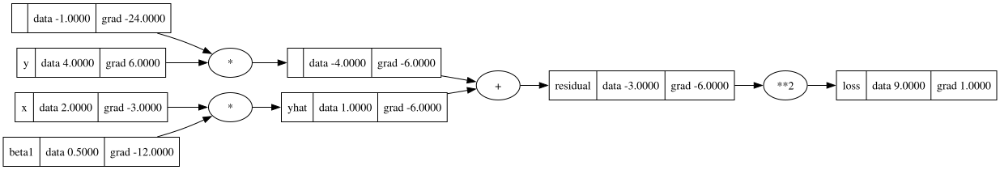

In [89]:
from micrograd.engine import Value

# -----------------
# One datapoint
# -----------------
x = Value(2.0)
x.label = 'x'

y = Value(4.0)
y.label = 'y'

# parameter
beta1 = Value(0.5)
beta1.label = 'beta1'

# -----------------
# Forward pass
# -----------------
yhat = beta1 * x
yhat.label = 'yhat'

residual = yhat - y
residual.label = 'residual'

loss = residual ** 2
loss.label = 'loss'

# -----------------
# Backward pass
# -----------------
loss.backward()

# visualize
draw_dot(loss)

Händische Berechnung zur Verifikation, dass Gradientenabstieg funktioniert

In [90]:
beta1 = Value(0.5)
x = 2; y = 4;
loss = (beta1 * x - y) ** 2
loss.backward()
print(f"loss ist {loss.data}")
print(f"beta1.grad ist {beta1.grad}")

loss ist 9.0
beta1.grad ist -12.0


In [91]:
beta1.data = beta1.data - 0.01 * beta1.grad
loss = (beta1 * x - y) ** 2

print(f"loss ist jetzt {loss.data}")

loss ist jetzt 7.617599999999999


Komplizierterer Graph für lineare Regression mit drei Datenpunkten

In [92]:
from graphviz import Digraph

def trace(root):
    # builds a set of all nodes and edges in a graph
    nodes, edges = set(), set()

    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)

    build(root)
    return nodes, edges


def draw_dot(root):
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'})

    nodes, edges = trace(root)
    for n in nodes:
        uid = str(id(n))

        # node label: name, data, grad
        dot.node(
            name=uid,
            label=f"{{ {n.label} | data {n.data:.4f} | grad {n.grad:.4f} }}",
            shape='record'
        )

        if n._op:
            # operation node
            dot.node(name=uid + n._op, label=n._op)
            dot.edge(uid + n._op, uid)

    for n1, n2 in edges:
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)

    return dot

In [93]:
from matplotlib.pylab import beta
from micrograd.engine import Value
import numpy as np

# small dataset just for the graph
x_small = [1.0, 2.0, 3.0]
y_small = [2.2, 3.9, 6.1]

beta1 = Value(0.5)
beta1.label = 'beta1'

loss = Value(0.0)
loss.label = 'loss_start'

for i, (xi, yi) in enumerate(zip(x_small, y_small), start=1):
    x_i = Value(xi)
    x_i.label = f'x{i}'
    
    y_i = Value(yi)
    y_i.label = f'y{i}'

    yhat_i = beta1 * x_i
    yhat_i.label = f'yhat{i}'

    residual_i = yhat_i - y_i
    residual_i.label = f'resid{i}'

    sq_i = residual_i ** 2
    sq_i.label = f'sq{i}'

    loss = loss + sq_i
    loss.label = f'loss_after_{i}'

# backprop so gradients appear in the graph
loss.backward()

draw_dot(loss)

AttributeError: 'Value' object has no attribute 'label'

Gleich wie oben: Händische Berechnung zur Verifikation, dass Gradientenabstieg funktioniert

In [94]:
beta1 = Value(0.5)
x1 = Value(x_small[0]); y1 = Value(y_small[0]);
x2 = Value(x_small[1]); y2 = Value(y_small[1]);
x3 = Value(x_small[2]); y3 = Value(y_small[2]);
loss = (beta1 * x1 - y1) ** 2 + (beta1 * x2 - y2) ** 2 + (beta1 * x3 - y3) ** 2
loss.backward()
print(f"loss ist {loss.data:.4f}")
print(f"beta1.grad ist {beta1.grad:.4f}")

loss ist 32.4600
beta1.grad ist -42.6000


In [95]:
beta1.data = beta1.data - 0.01 * beta1.grad
loss = (beta1 * x1 - y1) ** 2 + (beta1 * x2 - y2) ** 2 + (beta1 * x3 - y3) ** 2

print(f"loss ist jetzt {loss.data:.4f}")

loss ist jetzt 16.8531


#### Micrograd für lineare Regression mit zwei Parametern

Das Modell

In [96]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
from micrograd.engine import Value

import matplotlib as mpl
mpl.rcParams['animation.embed_limit'] = 50

# -----------------
# Same data style as before
# -----------------
np.random.seed(42)

n = 10
x = np.linspace(1, 10, n)
true_beta1 = 2.0
true_beta0 = -5.0
y = true_beta1 * x + true_beta0 + np.random.normal(0, 1, n)

# -----------------
# Loss function
# -----------------
def sse_loss(beta1, beta0, x_data, y_data):
    """
    Sum of squared errors for y = beta1 * x + beta0
    beta1 and beta0 are micrograd Value objects
    """
    loss = Value(0.0)
    for xi, yi in zip(x_data, y_data):
        yhat = beta1 * xi + beta0
        residual = yhat - yi
        loss = loss + residual**2
    return loss

Fehlerminimierung durch Gradientenabstieg

In [97]:
# -----------------
# Training
# -----------------
beta1 = Value(0.0)
beta0 = Value(0.0)

learning_rate = 0.002
steps = 550

beta1_history = []
beta0_history = []
loss_history = []

for step in range(steps):
    loss = sse_loss(beta1, beta0, x, y)

    beta1.grad = 0.0
    beta0.grad = 0.0
    loss.backward()

    beta1_history.append(beta1.data)
    beta0_history.append(beta0.data)
    loss_history.append(loss.data)

    beta1.data = beta1.data - learning_rate * beta1.grad
    beta0.data = beta0.data - learning_rate * beta0.grad
    
print(f"final beta1 = {beta1.data:.4f}")
print(f"final beta0 = {beta0.data:.4f}")
print(f"final SSE   = {loss_history[-1]:.4f}")

final beta1 = 1.9866
final beta0 = -4.4685
final SSE   = 4.7052


Visuelle Darstellung

In [98]:
# -----------------
# Error surface on a grid
# -----------------
beta1_grid = np.linspace(-0.5, 3.5, 160)
beta0_grid = np.linspace(-6.0, 6.0, 160)

B1, B0 = np.meshgrid(beta1_grid, beta0_grid)
Z = np.zeros_like(B1)

for i in range(B1.shape[0]):
    for j in range(B1.shape[1]):
        y_pred = B1[i, j] * x + B0[i, j]
        Z[i, j] = np.sum((y - y_pred)**2)

# closed-form solution for reference
x_mean = np.mean(x)
y_mean = np.mean(y)
beta1_hat = np.sum((x - x_mean) * (y - y_mean)) / np.sum((x - x_mean)**2)
beta0_hat = y_mean - beta1_hat * x_mean

frame_idx = list(range(0, len(beta1_history), 5))
# -----------------
# Figure
# -----------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))

# ---- Left: data + current regression line
ax1.scatter(x, y, label="data", s=35)

x_line = np.linspace(0, 10.5, 200)
line, = ax1.plot(x_line, beta1_history[0] * x_line + beta0_history[0], label="y = beta1 x + beta0")

title1 = ax1.set_title("")
ax1.set_xlabel("x")
ax1.set_ylabel("y")
ax1.legend(loc="upper left")
ax1.set_xlim(0, 10.5)

y_min = min(y.min(), (beta1_grid.min() * x + beta0_grid.min()).min()) - 2
y_max = max(y.max(), (beta1_grid.max() * x + beta0_grid.max()).max()) + 2
ax1.set_ylim(y_min, y_max)

# ---- Right: contour plot of SSE(beta1, beta0)
contours = ax2.contour(B1, B0, Z, levels=10)
ax2.clabel(contours, inline=True, fontsize=8)

trace_line, = ax2.plot([], [], linewidth=2, label="gradient descent path")
point, = ax2.plot([beta1_history[0]], [beta0_history[0]], marker="o")

ax2.plot(beta1_hat, beta0_hat, marker="x", markersize=10, linestyle="None", label="minimum")

ax2.set_xlabel("beta1")
ax2.set_ylabel("beta0")
ax2.set_title("SSE contour plot")
ax2.legend(loc="upper right")
ax2.set_xlim(beta1_grid.min(), beta1_grid.max())
ax2.set_ylim(beta0_grid.min(), beta0_grid.max())

# -----------------
# Animation update
# -----------------
def update(frame):
    b1 = beta1_history[frame]
    b0 = beta0_history[frame]
    loss = loss_history[frame]

    line.set_ydata(b1 * x_line + b0)
    title1.set_text(f"step = {frame}   |   beta1 = {b1:.3f}   |   beta0 = {b0:.3f}   |   SSE = {loss:.2f}")

    trace_line.set_data(beta1_history[:frame+1], beta0_history[:frame+1])
    point.set_data([b1], [b0])

    return [line, trace_line, point, title1]
    
ani = FuncAnimation(
    fig,
    update,
    frames=frame_idx,
    interval=100,
    blit=False
)


plt.tight_layout()
plt.close(fig)
HTML(ani.to_jshtml())

#### Klassifikationsdemo mit nur einem Neuron

Das Netz und die Daten

Startwerte der Parameter im Neuron:
param 0: -0.9473
param 1: 0.5627
param 2: 0.0000


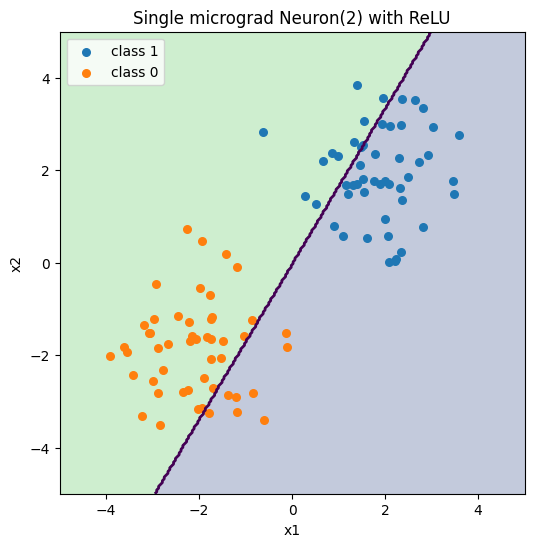

In [99]:
import numpy as np
import matplotlib.pyplot as plt

from micrograd.engine import Value
from micrograd import nn

# -----------------
# Simple linearly separable dataset
# -----------------
np.random.seed(42)

n = 50
X_pos = np.random.randn(n, 2) + np.array([2, 2])
X_neg = np.random.randn(n, 2) + np.array([-2, -2])

X = np.vstack([X_pos, X_neg])
y = np.array([1]*n + [0]*n)

# -----------------
# Karpathy micrograd neuron
# -----------------
# IMPORTANT:
# In micrograd, Neuron(nin, nonlin=True) uses ReLU by default.
import random
random.seed(420)
neuron = nn.Neuron(2, nonlin=True)

# Show random initialization
params = neuron.parameters()
print("Startwerte der Parameter im Neuron:")
for i, p in enumerate(params):
    print(f"param {i}: {p.data:.4f}")

# -----------------
# Evaluate neuron on a grid
# -----------------
xx, yy = np.meshgrid(
    np.linspace(-5, 5, 250),
    np.linspace(-5, 5, 250)
)

Z = np.zeros_like(xx)

for i in range(xx.shape[0]):
    for j in range(xx.shape[1]):
        x1 = Value(float(xx[i, j]))
        x2 = Value(float(yy[i, j]))
        out = neuron([x1, x2])     # actual Karpathy Neuron call
        Z[i, j] = out.data

# -----------------
# Plot
# -----------------
plt.figure(figsize=(6, 6))

# Shade regions by whether neuron output is positive
plt.contourf(xx, yy, Z > 0, levels=[-0.5, 0.5, 1.5], alpha=0.3)

# Optional: also show the zero-output boundary itself
plt.contour(xx, yy, Z, levels=[0], linewidths=2)

# Plot the dataset
plt.scatter(X_pos[:, 0], X_pos[:, 1], label="class 1", s=30)
plt.scatter(X_neg[:, 0], X_neg[:, 1], label="class 0", s=30)

plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Single micrograd Neuron(2) with ReLU")
plt.legend(loc="upper left")
plt.xlim(-5, 5)
plt.ylim(-5, 5)
plt.show()

Trainieren des einzelnen Neurons, wiederum durch Gradientenabstieg

In [100]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
import matplotlib as mpl
import random

from micrograd.engine import Value
from micrograd import nn

mpl.rcParams['animation.embed_limit'] = 50

# -----------------
# Seeds
# -----------------
np.random.seed(42)
random.seed(420)

# -----------------
# Dataset
# -----------------
n = 50
X_pos = np.random.randn(n, 2) + np.array([2, 2])
X_neg = np.random.randn(n, 2) + np.array([-2, -2])

X = np.vstack([X_pos, X_neg])
y = np.array([1]*n + [-1]*n)

# convert to Value inputs once
inputs = [[Value(float(x1)), Value(float(x2))] for x1, x2 in X]

# -----------------
# Model
# -----------------
model = nn.Neuron(2, nonlin=False)   # linear neuron (no ReLU!)

# -----------------
# Training
# -----------------
learning_rate = 0.05
epochs = 300

param_hist = []
loss_hist = []

for epoch in range(epochs):

    # forward pass
    scores = list(map(model, inputs))

    losses = [(1 + -yi * scorei).relu() for yi, scorei in zip(y, scores)]
    data_loss = sum(losses) * (1.0 / len(losses))

    # L2 regularization
    alpha = 0 #1e-4
    reg_loss = alpha * sum((p*p for p in model.parameters()))

    total_loss = data_loss + reg_loss

    # backward
    for p in model.parameters():
        p.grad = 0.0
    total_loss.backward()

    # record parameters
    w1 = model.w[0].data
    w2 = model.w[1].data
    b  = model.b.data

    param_hist.append((w1, w2, b))
    loss_hist.append(total_loss.data)

    # update
    for p in model.parameters():
        p.data -= learning_rate * p.grad

print("final loss:", loss_hist[-1])

final loss: 0.0


Darstellung des Trainingsfortschritts

In [101]:
# -----------------
# Figure
# -----------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

# ---- Left: data + boundary
ax1.scatter(X_pos[:, 0], X_pos[:, 1], label="class +1", s=30)
ax1.scatter(X_neg[:, 0], X_neg[:, 1], label="class -1", s=30)

boundary_line, = ax1.plot([], [], 'k--', label="decision boundary")

ax1.set_xlim(-5, 5)
ax1.set_ylim(-5, 5)
ax1.legend(loc="upper left")
title1 = ax1.set_title("")

# ---- Right: loss curve
ax2.set_xlim(0, len(loss_hist))
ax2.set_ylim(0, max(loss_hist) * 1.1)

loss_line, = ax2.plot([], [], label="loss")
point, = ax2.plot([], [], 'o')

ax2.set_xlabel("epoch")
ax2.set_ylabel("loss")
ax2.legend(loc="upper right")

# -----------------
# Animation update
# -----------------
def update(frame):
    w1, w2, b = param_hist[frame]

    x_line = np.linspace(-5, 5, 100)
    y_line = -(w1 * x_line + b) / w2
    boundary_line.set_data(x_line, y_line)

    title1.set_text(f"epoch {frame} | w1={w1:.2f}, w2={w2:.2f}, b={b:.2f}")

    loss_line.set_data(range(frame + 1), loss_hist[:frame + 1])
    point.set_data([frame], [loss_hist[frame]])

    return [boundary_line, loss_line, point, title1]
    
frame_idx = list(range(0, len(loss_hist), 5))
ani = FuncAnimation(
    fig,
    update,
    frames=frame_idx,
    interval=100,
    blit=False
)

plt.tight_layout()
plt.close(fig)
HTML(ani.to_jshtml())

In [102]:
import random
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [103]:
from micrograd.engine import Value
from micrograd.nn import Neuron, Layer, MLP

In [104]:
np.random.seed(1337)
random.seed(1337)

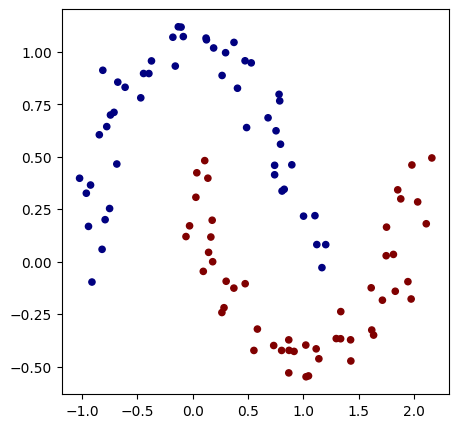

In [105]:
# make up a dataset

from sklearn.datasets import make_moons, make_blobs
X, y = make_moons(n_samples=100, noise=0.1)

y = y*2 - 1 # make y be -1 or 1
# visualize in 2D
plt.figure(figsize=(5,5))
plt.scatter(X[:,0], X[:,1], c=y, s=20, cmap='jet')

In [106]:
# initialize a model 
model = MLP(2, [16, 16, 1]) # 2-layer neural network
print(model)
print("number of parameters", len(model.parameters()))

MLP of [Layer of [ReLUNeuron(2), ReLUNeuron(2), ReLUNeuron(2), ReLUNeuron(2), ReLUNeuron(2), ReLUNeuron(2), ReLUNeuron(2), ReLUNeuron(2), ReLUNeuron(2), ReLUNeuron(2), ReLUNeuron(2), ReLUNeuron(2), ReLUNeuron(2), ReLUNeuron(2), ReLUNeuron(2), ReLUNeuron(2)], Layer of [ReLUNeuron(16), ReLUNeuron(16), ReLUNeuron(16), ReLUNeuron(16), ReLUNeuron(16), ReLUNeuron(16), ReLUNeuron(16), ReLUNeuron(16), ReLUNeuron(16), ReLUNeuron(16), ReLUNeuron(16), ReLUNeuron(16), ReLUNeuron(16), ReLUNeuron(16), ReLUNeuron(16), ReLUNeuron(16)], Layer of [LinearNeuron(16)]]
number of parameters 337


In [107]:
# loss function
def loss(batch_size=None):
    
    # inline DataLoader :)
    if batch_size is None:
        Xb, yb = X, y
    else:
        ri = np.random.permutation(X.shape[0])[:batch_size]
        Xb, yb = X[ri], y[ri]
    inputs = [list(map(Value, xrow)) for xrow in Xb]
    
    # forward the model to get scores
    scores = list(map(model, inputs))
    
    # svm "max-margin" loss
    losses = [(1 + -yi*scorei).relu() for yi, scorei in zip(yb, scores)]
    data_loss = sum(losses) * (1.0 / len(losses))
    # L2 regularization
    alpha = 1e-4
    reg_loss = alpha * sum((p*p for p in model.parameters()))
    total_loss = data_loss + reg_loss
    
    # also get accuracy
    accuracy = [(yi > 0) == (scorei.data > 0) for yi, scorei in zip(yb, scores)]
    return total_loss, sum(accuracy) / len(accuracy)

total_loss, acc = loss()
print(total_loss, acc)

Value(data=0.8958441028683222, grad=0) 0.5


In [108]:
import numpy as np
import matplotlib.pyplot as plt
from micrograd.engine import Value
from IPython.display import clear_output

def plot_decision_region(model, X, y, step, grid_points=80):
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, grid_points),
        np.linspace(y_min, y_max, grid_points)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]

    # just sign → classification
    preds = []
    for x1, x2 in grid:
        score = model([Value(float(x1)), Value(float(x2))])
        preds.append(1 if score.data > 0 else -1)

    Z = np.array(preds).reshape(xx.shape)

    clear_output(wait=True)
    plt.figure(figsize=(5, 5))

    # two-color background
    plt.pcolormesh(xx, yy, Z, shading='auto', cmap='coolwarm', alpha=0.3)

    # data points
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm', edgecolors='k')

    plt.title(f"Decision region at epoch {step}")
    plt.xlim(x_min, x_max)
    plt.ylim(y_min, y_max)

    plt.show()

In [109]:
# optimization
import copy

snapshots = []
loss_hist = []
acc_hist = []
epoch_hist = []

for k in range(100):
    total_loss, acc = loss()

    model.zero_grad()
    total_loss.backward()

    learning_rate = 1.0 - 0.9 * k / 100
    for p in model.parameters():
        p.data -= learning_rate * p.grad

    print(f"step {k} loss {total_loss.data}, accuracy {acc*100}%")

    if k % 5 == 0:
        snapshots.append([p.data for p in model.parameters()])
        loss_hist.append(total_loss.data)
        acc_hist.append(acc)
        epoch_hist.append(k)

step 0 loss 0.8958441028683222, accuracy 50.0%
step 1 loss 1.723590533697202, accuracy 81.0%
step 2 loss 0.7429006313851131, accuracy 77.0%
step 3 loss 0.7705641260584202, accuracy 82.0%
step 4 loss 0.3692793385976538, accuracy 84.0%
step 5 loss 0.31354548191852194, accuracy 86.0%
step 6 loss 0.2814234349772435, accuracy 89.0%
step 7 loss 0.2688873331398391, accuracy 91.0%
step 8 loss 0.2567147286057416, accuracy 91.0%
step 9 loss 0.27048625516379227, accuracy 91.0%
step 10 loss 0.2450702385365804, accuracy 91.0%
step 11 loss 0.2509905529791504, accuracy 92.0%
step 12 loss 0.21560951851922946, accuracy 91.0%
step 13 loss 0.23090378446402735, accuracy 93.0%
step 14 loss 0.2015215122789945, accuracy 92.0%
step 15 loss 0.22574506279282222, accuracy 93.0%
step 16 loss 0.19447987596204105, accuracy 92.0%
step 17 loss 0.21089496199246366, accuracy 93.0%
step 18 loss 0.15983077356303602, accuracy 94.0%
step 19 loss 0.1845374874688393, accuracy 93.0%
step 20 loss 0.18977522856087634, accuracy 

In [110]:
def load_params(model, flat_params):
    for p, val in zip(model.parameters(), flat_params):
        p.data = val

In [111]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
from micrograd.engine import Value
import matplotlib as mpl

mpl.rcParams['animation.embed_limit'] = 50  # MB

# grid for background classification
x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

grid_points = 80
xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, grid_points),
    np.linspace(y_min, y_max, grid_points)
)
grid = np.c_[xx.ravel(), yy.ravel()]

fig, ax = plt.subplots(figsize=(5, 5))

from IPython.display import clear_output

cached_Z = []

for i, params in enumerate(snapshots):
    clear_output(wait=True)
    print(f"Precomputing frame {i+1}/{len(snapshots)}")

    load_params(model, params)

    preds = []
    for x1, x2 in grid:
        score = model([Value(float(x1)), Value(float(x2))])
        preds.append(1 if score.data > 0 else -1)

    Z = np.array(preds).reshape(xx.shape)
    cached_Z.append(Z)

clear_output(wait=True)
print("Precomputing done.")


def update(frame):
    Z = cached_Z[frame]

    ax.clear()
    ax.pcolormesh(xx, yy, Z, shading='auto', cmap='coolwarm', alpha=0.3)
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm', edgecolors='k')
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_title(
        f"epoch {epoch_hist[frame]} | loss {loss_hist[frame]:.3f} | acc {100*acc_hist[frame]:.1f}%"
    )



ani = FuncAnimation(
    fig,
    update,
    frames=len(snapshots),
    interval=300,
    blit=False
)

plt.close(fig)
HTML(ani.to_jshtml())

Precomputing done.


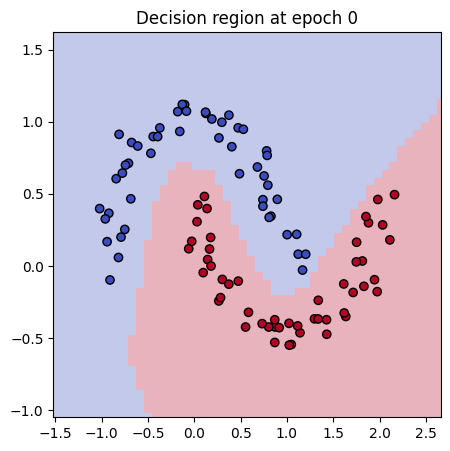

In [112]:
plot_decision_region(model, X, y, step=0, grid_points=50)

#### Klassifikationsdemo mit einem ganzen neuronalen Netz (adaptiert nach Vorlage von Andrej Karpathy)

In [113]:
import random
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

from micrograd.engine import Value
from micrograd.nn import Neuron, Layer, MLP

np.random.seed(1337)
random.seed(1337)

Die Daten

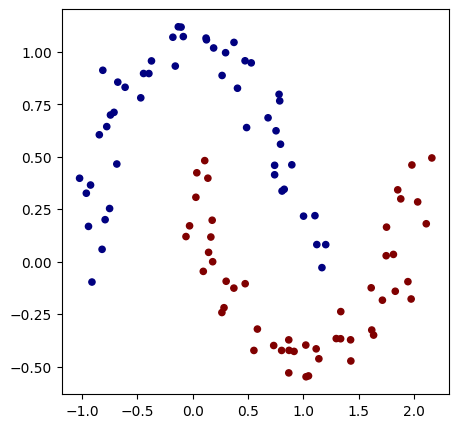

In [114]:
# make up a dataset

from sklearn.datasets import make_moons, make_blobs
X, y = make_moons(n_samples=100, noise=0.1)

y = y*2 - 1 # make y be -1 or 1
# visualize in 2D
plt.figure(figsize=(5,5))
plt.scatter(X[:,0], X[:,1], c=y, s=20, cmap='jet')

Das Modell

In [115]:
# initialize a model 
model = MLP(2, [8,4, 1]) # 2-layer neural network
print(model)
print("number of parameters", len(model.parameters()))

MLP of [Layer of [ReLUNeuron(2), ReLUNeuron(2), ReLUNeuron(2), ReLUNeuron(2), ReLUNeuron(2), ReLUNeuron(2), ReLUNeuron(2), ReLUNeuron(2)], Layer of [ReLUNeuron(8), ReLUNeuron(8), ReLUNeuron(8), ReLUNeuron(8)], Layer of [LinearNeuron(4)]]
number of parameters 65


Die Fehlerfunktion

In [116]:
# loss function
def loss(batch_size=None):
    
    # inline DataLoader :)
    if batch_size is None:
        Xb, yb = X, y
    else:
        ri = np.random.permutation(X.shape[0])[:batch_size]
        Xb, yb = X[ri], y[ri]
    inputs = [list(map(Value, xrow)) for xrow in Xb]
    
    # forward the model to get scores
    scores = list(map(model, inputs))
    
    # svm "max-margin" loss
    losses = [(1 + -yi*scorei).relu() for yi, scorei in zip(yb, scores)]
    data_loss = sum(losses) * (1.0 / len(losses))
    # L2 regularization
    alpha = 0# 1e-4
    reg_loss = alpha * sum((p*p for p in model.parameters()))
    total_loss = data_loss + reg_loss
    
    # also get accuracy
    accuracy = [(yi > 0) == (scorei.data > 0) for yi, scorei in zip(yb, scores)]
    return total_loss, sum(accuracy) / len(accuracy)

total_loss, acc = loss()
print(total_loss, acc)

Value(data=1.27043768975022, grad=0) 0.5


Vorbereitung der visuellen Darstellung

In [117]:
import numpy as np
import matplotlib.pyplot as plt
from micrograd.engine import Value
from IPython.display import clear_output

def plot_decision_region(model, X, y, step, grid_points=80):
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, grid_points),
        np.linspace(y_min, y_max, grid_points)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]

    # just sign → classification
    preds = []
    for x1, x2 in grid:
        score = model([Value(float(x1)), Value(float(x2))])
        preds.append(1 if score.data > 0 else -1)

    Z = np.array(preds).reshape(xx.shape)

    clear_output(wait=True)
    plt.figure(figsize=(5, 5))

    # two-color background
    plt.pcolormesh(xx, yy, Z, shading='auto', cmap='coolwarm', alpha=0.3)

    # data points
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm', edgecolors='k')

    plt.title(f"Decision region at epoch {step}")
    plt.xlim(x_min, x_max)
    plt.ylim(y_min, y_max)

    plt.show()

Trainieren des neuronalen Netzes

In [118]:
# optimization
import copy

snapshots = []
loss_hist = []
acc_hist = []
epoch_hist = []

for k in range(250):
    total_loss, acc = loss()

    model.zero_grad()
    total_loss.backward()

    #learning_rate = 1.0 - 0.9 * k / 100
    learning_rate = 0.3
    for p in model.parameters():
        p.data -= learning_rate * p.grad

    print(f"step {k} loss {total_loss.data}, accuracy {acc*100}%")

    if k % 10 == 0:
        snapshots.append([p.data for p in model.parameters()])
        loss_hist.append(total_loss.data)
        acc_hist.append(acc)
        epoch_hist.append(k)

step 0 loss 1.27043768975022, accuracy 50.0%
step 1 loss 1.0415993621033333, accuracy 48.0%
step 2 loss 0.9060893720232441, accuracy 41.0%
step 3 loss 0.8269083645454159, accuracy 41.0%
step 4 loss 0.7726401948609402, accuracy 64.0%
step 5 loss 0.7303227240903779, accuracy 74.0%
step 6 loss 0.6921330224001103, accuracy 75.0%
step 7 loss 0.6561265691488956, accuracy 77.0%
step 8 loss 0.6218948062387086, accuracy 77.0%
step 9 loss 0.588468044895372, accuracy 80.0%
step 10 loss 0.5539551537818924, accuracy 80.0%
step 11 loss 0.5164122350152273, accuracy 82.0%
step 12 loss 0.47575333216905225, accuracy 79.0%
step 13 loss 0.4332221006948499, accuracy 81.0%
step 14 loss 0.3853828160035277, accuracy 79.0%
step 15 loss 0.3651422778499688, accuracy 82.0%
step 16 loss 0.35704647718600663, accuracy 82.0%
step 17 loss 0.3506461738200182, accuracy 83.0%
step 18 loss 0.3448227487788142, accuracy 83.0%
step 19 loss 0.339726938352697, accuracy 83.0%
step 20 loss 0.33528355208219657, accuracy 84.0%
ste

In [119]:
def load_params(model, flat_params):
    for p, val in zip(model.parameters(), flat_params):
        p.data = val

Berechnung der Animation

In [120]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
from micrograd.engine import Value
import matplotlib as mpl

mpl.rcParams['animation.embed_limit'] = 50  # MB

# grid for background classification
x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

grid_points = 80
xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, grid_points),
    np.linspace(y_min, y_max, grid_points)
)
grid = np.c_[xx.ravel(), yy.ravel()]

fig, ax = plt.subplots(figsize=(5, 5))

from IPython.display import clear_output

cached_Z = []

for i, params in enumerate(snapshots):
    clear_output(wait=True)
    print(f"Precomputing frame {i+1}/{len(snapshots)}")

    load_params(model, params)

    preds = []
    for x1, x2 in grid:
        score = model([Value(float(x1)), Value(float(x2))])
        preds.append(1 if score.data > 0 else -1)

    Z = np.array(preds).reshape(xx.shape)
    cached_Z.append(Z)

clear_output(wait=True)
print("Precomputing done.")


def update(frame):
    Z = cached_Z[frame]

    ax.clear()
    ax.pcolormesh(xx, yy, Z, shading='auto', cmap='coolwarm', alpha=0.3)
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm', edgecolors='k')
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_title(
        f"epoch {epoch_hist[frame]} | loss {loss_hist[frame]:.3f} | acc {100*acc_hist[frame]:.1f}%"
    )



ani = FuncAnimation(
    fig,
    update,
    frames=len(snapshots),
    interval=300,
    blit=False
)

plt.close(fig)
HTML(ani.to_jshtml())

Precomputing done.


#### MNIST Klassifikation (eigenes Skript)

weiter mit /opt/pytorch-env/IAT-MNIST/mnist-pytorch.py